# Modelling a 1D function using Multi-Layered Perceptrons

This workshop will introduce you to:
- Building neural network classes using [PyTorch](https://pytorch.org/tutorials/beginner/basics/intro.html).
- Formatting data and creating a training loop.
- Validating network performance and investigating the effect of hyperparameters.

This will be followed by a separate notebook covering a 2D function. Later, you will use what you have learned to train a $\Delta$-ML model on extended $\pi$-conjugated molecules using the Morgan fingerprint. 

Read through this notebook, a framework script is provided at the end for you to modify the code and attempt the tasks. Full coding solutions are available in the .py files provided in the workshop data folder, but try to answer the tasks yourself first by searching for online resources.

***
First, ensure you have the required packages for the below imports in a new or existing python environment. Update to your relevant directory in os.chdir. See the Appendix for some help.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.modules import Module
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.interpolate import griddata
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
from ipywidgets import interact

#%%script false --no-raise-error # Can stop cells running

# Change to the directory you put the workshop files
os.chdir("C:/Users/adamc/Intro-to-networks-workshop/dml_workshop") # for windows
#os.chdir("Change this to the working directory path with this file in") # for windows

# Local .py file import
from stats_and_plot_functions import normalize_data, mean_squared_error, plot_train_loss, doubleplot, calc_num_net_parameters

Consider a 1D function:     $y=\frac{2x\ }{5}+\frac{sin\left(5x\right)}{2}+sin\left(3x\right)+10cos\left(x\right)e^{-x/10}+7$

We can use a neural network to model this function and simulate training data by randomly sampling the true function.  We want to build a Multi-Layered Perceptron (MLP), which is a very simple yet powerful algorithm. First let’s create a 1-layer and 2-layer network,  sample our data, and build a training loop.

***

Below are the classes for a Single-Layer Perceptron and a (2-layer) Multi-Layer Perceptron (MLP):

In [2]:
class SingleLayerPerceptron(nn.Module):
    """
    A simple single-layer perceptron model with one hidden layer.

    Parameters
    ----------
    input_dim : int
        Number of input features.
    hidden_dim : int, optional
        Number of neurons in the hidden layer (default is 100).
    output_dim : int, optional
        Number of output neurons (default is 1).
    activation_func : torch.nn.Module, optional
        Activation function applied after the hidden layer (default is None).

    Methods
    -------
    forward(x)
        Performs forward propagation through the network. Returns X, torch.Tensor object.
    """
    def __init__(self,
                 input_dim:  int,
                 hidden_dim: int = 100,
                 output_dim: int = 1,
                 activation_func=None
                 ): 
        super(SingleLayerPerceptron, self).__init__()
        
        # Define the layer variables and activation functions within class
        self.activation_func=activation_func
        self.hidden_layer = nn.Linear(input_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, output_dim)

    def forward(self, x): # Propagate data through layers when class forward method is called
        x = x.view(x.size(0), -1)  # Flatten input if necessary
        x = self.hidden_layer(x)
        if self.activation_func is not None:
            x = self.activation_func(x)
        x = self.output_layer(x)
        return x  


class MLP_2layer(nn.Module):
    """
    A Multi-Layer Perceptron (MLP) with two hidden layers.
    
    Parameters
    ----------
    input_dim : int
        Number of input features.
    output_dim : int, optional
        Number of output neurons.
    neurons : list, optional
        List containing the number of neurons in each hidden layer (default is [200, 100]).
    activation_func : torch.nn.Module, optional
        Activation function applied after each hidden layer (default is ReLU).
    
    Methods
    -------
    forward(x)
        Performs forward propagation through the network. Returns X, torch.Tensor object.
    """
    
    def __init__(self,
                 input_dim:  int,
                 output_dim: int,
                 neurons:    list = [200,100],
                 activation_func  = None
                 ):
        super(MLP_2layer, self).__init__()
        if activation_func is None: activation_func=nn.ReLU()
        
        # Building the network object by hardcoding 2 layers
        self.layers = nn.Sequential( # Sequential pytorch container, forward method can be directly applied 
            nn.Linear(input_dim, neurons[0]),   # Add 1st hidden layer
            activation_func,                    # Apply activation to layer
            nn.Linear(neurons[0], neurons[1]),  # Add 2nd hidden layer
            activation_func,                    # Apply activation to layer
            nn.Linear(neurons[1], output_dim) # Linear output layer with no activation function
        )
    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = self.layers(x)        # Apply data to Sequential object that passes data through each layer for you
        return x

And now create some functions to sample the data 

In [3]:
def compute_y(x): 
    return ((0.4*x + 0.5*np.sin(5*x) + np.sin(3*x)) + 10*np.cos(x)*np.exp(-0.1*x)) + 7

def sample_x_values(x_min, x_max, dx, num_samples):
    possible_x = np.arange(x_min, x_max + dx, dx)  # generate contiguous possible x values
    return np.random.choice(possible_x, num_samples, replace=False)  # Randomly sample x vals

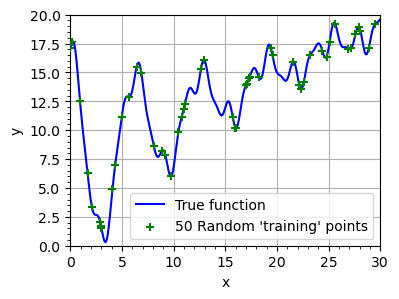

In [4]:
x_min, x_max, dx = 0, 30, 0.001
num_samples = 50
x_values = np.linspace(x_min, x_max, 300)
y_values = compute_y(x_values)
# Randomly sample x values and compute corresponding y values
sampled_x = sample_x_values(x_min, x_max, dx, num_samples)
sampled_y = compute_y(sampled_x)
%matplotlib inline
doubleplot(x_values, y_values, sampled_x, sampled_y,labels=["x","y","True function",str(num_samples)+" Random 'training' points",""], lims=[[0,30],[0,20]], figsize=(4,3))

As you can see in the figure, we have randomly sampled $N=50$ points from the true function, which is meant to emulate our training data. However, 50 points clearly is not enough to fit any sort of reasonable model to the data.

I've only put 25 epochs here to keep training short for this demonstration. The next few cells will:

- Initialise a 2-layer model and its hyperparameters.
- Sample the training data randomly and normalise the input (X_train) and target (y_train) that will be used by the network during training.
- Sample the validation data at regular intervals and normalise this data using the $\mu$ and $\sigma$ from the training data (It is important to do it this way to [avoid data leakage](https://www.ibm.com/think/topics/data-leakage-machine-learning))
- Format these into PyTorch DataLoader container and shuffle the training data.

Note that we won't use k-fold cross-validation here; it doesn't really apply as we are sampling our 'ideal' 1D function. Also, just in this demonstration, our validation data will double up as our unseen testing set. However, in reality you would split off validation data from the original training data so you'd have: Training data, validation data (for evaluation during training), and testing data (completely separate from training, used for evaluation after training)

In [5]:
# Hyperparameters
learning_rate = 0.001 # The degree of parameter update during backpropagation. This is the global value, but can change within the optimiser.
num_epochs = 25 # Number of times the whole dataset will be passed through.
batch_size = 32 # The number of training points whose loss will be averaged together.
# See list of different activation functions https://pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity
activation = nn.ReLU() # Rectified Linear Unit
criterion = nn.MSELoss() # Mean Squared Error loss
neurons=[200,100]

# Initialize 2-layer model
model = MLP_2layer(input_dim=1,output_dim=1,neurons=neurons, activation_func=activation)
optimizer = optim.AdamW(model.parameters(), lr=learning_rate) 

In [6]:
# Training data params
training_samples=20000 
x_min, x_max=0,30

# Create and preprocess training data into 32 bit floats for PyTorch torch.Tensor objects
x_vals_train=sample_x_values(x_min, x_max, dx=0.00001, num_samples=training_samples).astype(np.float32)
y_vals_train = compute_y(x_vals_train).astype(np.float32)
x_vals_train_normalized, x_mean, x_std = normalize_data(x_vals_train)
y_vals_train_normalized, y_mean, y_std = normalize_data(y_vals_train)
X_train = torch.tensor(x_vals_train_normalized.reshape(len(x_vals_train),1), device='cpu')
y_train = torch.tensor(y_vals_train_normalized.reshape(len(y_vals_train),1), device='cpu')

# Create Validation data. In this simple case we are just sampling the true function, but realisitically it is taken from
# shuffled training data, i.e. for k-fold cross validation.
x_vals_valid=np.arange(x_min, x_max + 0.01, 0.1).astype(np.float32)
y_vals_valid = compute_y(x_vals_valid).astype(np.float32)
x_vals_valid_normalised = (x_vals_valid - x_mean) / x_std # DELIBERATELY Using normalisation from TRAINING data
y_vals_valid_normalised = (y_vals_valid - y_mean) / y_std # DELIBERATELY Using normalisation from TRAINING data
X_valid = torch.tensor(x_vals_valid_normalised.reshape(len(x_vals_valid),1), device='cpu')

# Format dataset using specialised PyTorch containers
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True) # Note we shuffle the training data



So by this point we have chosen hyperparameters to initialise our model, sampled 20k training points and pre-processed them. Now we need to create a training loop. Make sure you have a reasonable understanding of the steps within the training loop.


In [7]:
# Training loop
train_losses = []
for epoch in range(num_epochs):
    total_loss = 0.0
    model.train() # Tell model we are in training mode, weights can be modified, later we switch to evaluation mode
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        batch_X, batch_y      = batch_X.float(), batch_y.float()
        outputs               = model(batch_X).squeeze()  # Ensure output shape matches target
        loss                  = criterion(outputs, batch_y.squeeze())  # Compute loss
        loss.backward()  # Apply backpropagation
        optimizer.step()  # Update weights
        total_loss += loss.item()
    train_loss = total_loss / len(train_loader)
    train_losses.append(train_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}], Training Loss: {train_loss:.5f}")
print("\nTraining complete.")

Epoch [1/25], Training Loss: 0.38677
Epoch [2/25], Training Loss: 0.10508
Epoch [3/25], Training Loss: 0.03152
Epoch [4/25], Training Loss: 0.02505
Epoch [5/25], Training Loss: 0.02104
Epoch [6/25], Training Loss: 0.02139
Epoch [7/25], Training Loss: 0.01902
Epoch [8/25], Training Loss: 0.01966
Epoch [9/25], Training Loss: 0.01748
Epoch [10/25], Training Loss: 0.01739
Epoch [11/25], Training Loss: 0.01820
Epoch [12/25], Training Loss: 0.01698
Epoch [13/25], Training Loss: 0.01621
Epoch [14/25], Training Loss: 0.01614
Epoch [15/25], Training Loss: 0.01601
Epoch [16/25], Training Loss: 0.01523
Epoch [17/25], Training Loss: 0.01463
Epoch [18/25], Training Loss: 0.01501
Epoch [19/25], Training Loss: 0.01342
Epoch [20/25], Training Loss: 0.01420
Epoch [21/25], Training Loss: 0.01359
Epoch [22/25], Training Loss: 0.01338
Epoch [23/25], Training Loss: 0.01276
Epoch [24/25], Training Loss: 0.01310
Epoch [25/25], Training Loss: 0.01231

Training complete.


***
Once training is complete, we can evaluate our model using the validation data and plot the results, but first we will create a loss plot. Below is an example of what a loss plot looks like and how it tracks the training loss, validation loss and validation correlation over 200 epochs. This particular plot contains a straight vertical line to indicate the best performing iteration with respect to the correlation, as well as dashed lines to show to when the global learning rate was halved by a learning rate scheduler (see [A](https://medium.com/@theom/a-very-short-visual-introduction-to-learning-rate-schedulers-with-code-189eddffdb00) and [B](https://www.reddit.com/r/MachineLearning/comments/oy3co1/d_how_to_pick_a_learning_rate_scheduler/)), which in this particular case was [*ReduceLROnPlateau*](https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html). These plots can convey how training has progressed and lets you identify if the learning rate is too high/low, or if overfitting has occured.

Note the generalisation gap, which is a rough indication of how good the model should be at extrapolating to unseen testing data. Initially both the training and validation loss decrease at the same rate but as the network is more strictly fitted, they diverge, usually with the rate of improvement of validation loss slowing more than training loss. If the training loss keeps decreasing while validation loss stays the same (or even increases) then this is a clear indication that the model is overfitting.

<img src="loss_plot.png" alt="Loss Plot" width="500">

***

Run the cell below to see the loss plot of the trained network.


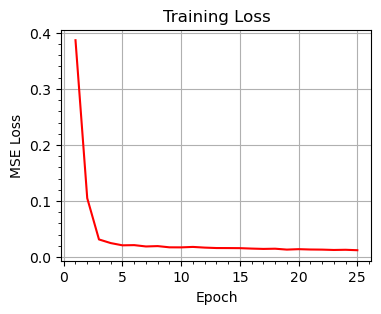

In [8]:
plot_train_loss(train_losses, valid_loss=None, labels=["Epoch", "MSE Loss", "Training Loss"], figsize=(4,3))

***
Next we can evaluate our model using the validation data and plot the predictions against the true values.

The full script is provided after the figure so you can test different settings yourself.
***

Final epoch [25/25], Training Loss: 0.01231, Valid Loss: 0.01168


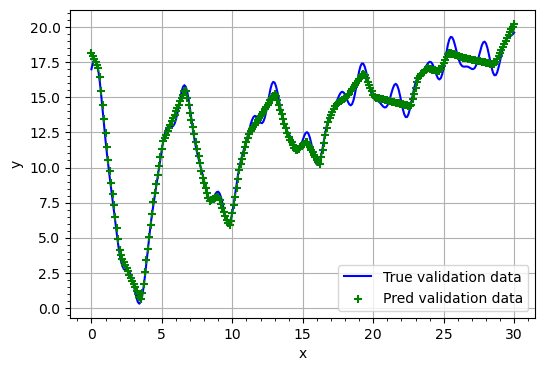

In [9]:
# Final evaluation step
model.eval() # Important to tell the model we're in evaluation model, ensures no weights are changed by accident
with torch.no_grad():
    valid_pred_normalized = np.squeeze(model(X_valid).detach().numpy())
y_vals_valid_predicted = (valid_pred_normalized * y_std) + y_mean # Unnormalise 
valid_loss = mean_squared_error(y_vals_valid_normalised, valid_pred_normalized)
print(f"Final epoch [{epoch+1}/{num_epochs}], Training Loss: {train_loss:.5f}, Valid Loss: {valid_loss:.5f}")
doubleplot(x_vals_valid, y_vals_valid, x_vals_valid, y_vals_valid_predicted,
           labels=["x","y","True validation data","Pred validation data",""], figsize=(6,4))

***
With only 25 epochs, the 2-layer network has managed to fit somewhat well but struggles to model the finer small amplitude variation. It is essentially just fitting a series of linear lines to the data, which to some extent is the basis of how Neural Networks work; glorified curve-fitting.

We can improve the training by adding more epochs. We also want to add a validation step within the training loop as the final epoch may not nescessarily be the best performing model according to the validation loss, this will help us limit overfitting. After training we can reload the model with the lowest validation loss. We can build our intuition of the models performance using different combinations of hyperparameters, trying some extremes settings and then finetuning to find a "good" set of hyperparameters.

For a decent conceptual overview of regression fitting networks for 1D functions, see [C](https://medium.com/@mfbenedetto/visualizing-function-approximation-using-dense-neural-networks-in-1d-part-i-1c3bdc51dc02) and [D](https://medium.com/@mfbenedetto/visualizing-function-approximation-using-dense-neural-networks-in-1d-part-ii-9ec29752fcda).

***
**Using the script in the cell below, complete the following tasks:**

*In class, only spend up to 40 minutes on these problems before moving onto the 2D notebook, but at least try to complete tasks 2 to 5*.
<br>
1) Run the Single Layer Perceptron and compare it to the 2-layer performance above. The predictions may be somewhat different, can you explain why? You might find that [C](https://medium.com/@mfbenedetto/visualizing-function-approximation-using-dense-neural-networks-in-1d-part-i-1c3bdc51dc02) and [D](https://medium.com/@mfbenedetto/visualizing-function-approximation-using-dense-neural-networks-in-1d-part-ii-9ec29752fcda) gives you an idea of what might be going on (see the appendix for the solution).
<br>
<br>
2) Add a validation step within the training loop and print out the validation loss with the training loss (don't forget *model.eval()* ).
<br>
<br>
3) Add a loss plot that includes validation data (plot_train_loss(train_losses, valid_loss=*Something...*, figsize=(4,3))).
<br>
<br>
4) Add functionality to track the epoch with the lowest validation loss to save and reload later for the final evaluation.
    - Use best_model_state = model.state_dict().copy() to save the best current model during training.
    - model.load_state_dict(best_model_state) to load the best model after training.
<br>
<br>
5) How low can you get the validation loss? Test out different combinations of the hyperparameters:
    -  Try a batch size of 1.
    -  Try 50 or more epochs (although anymore than 500 is overkill).
    -  Increase and decrease the learning rate.
    -  Change the activation function (try out SELU, LeakyRelu, Sigmoid and others from the list of [non-linear activation functions](https://pytorch.org/docs/stable/nn.html#non-linear-activations-weighted-sum-nonlinearity)).
    -  Increase and decrease the number of training samples (anymore than 500,000 is excessive and takes long to train).
    -  Hint: Maybe keep track of any hyperparameters you use and their losses by copy and pasting into a text file.
<br>
<br>
6) Create a new class called *MLP* that allows you to input any configuration of neurons and layers:
   - The input may look something like *neurons=[200, 100, 20, 10]* to indicate 4 layers of 200, 100, 20, and 10 neurons respectively.
   - Use may find [this resource](https://discuss.pytorch.org/t/how-to-create-mlp-model-with-arbitrary-number-of-hidden-layers/13124/5) useful.
   - Don't spend too long on this, a full solution with [dropout](https://machinelearningmastery.com/using-dropout-regularization-in-pytorch-models/) and custom activations per layer is available in *network_classes.py*.
***

Epoch [1/10], Training Loss: 0.40764
Epoch [2/10], Training Loss: 0.31072
Epoch [3/10], Training Loss: 0.23804
Epoch [4/10], Training Loss: 0.18380
Epoch [5/10], Training Loss: 0.14119
Epoch [6/10], Training Loss: 0.11093
Epoch [7/10], Training Loss: 0.08840
Epoch [8/10], Training Loss: 0.07225
Epoch [9/10], Training Loss: 0.06130
Epoch [10/10], Training Loss: 0.05275

Training complete.


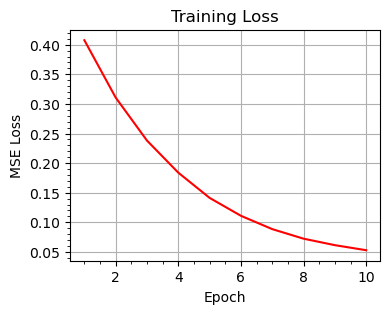

Number of training samples: 20000
For hyperparameters:
Neurons: 500 (501 parameters) 
Num Epochs: 10 
Learning Rate: 0.001 
Batch Size: 32 
Activation: ReLU()
Final epoch: [10/10], Training Loss: 0.05275, Valid Loss: 0.05801
Best Epoch and its train/valid loss??


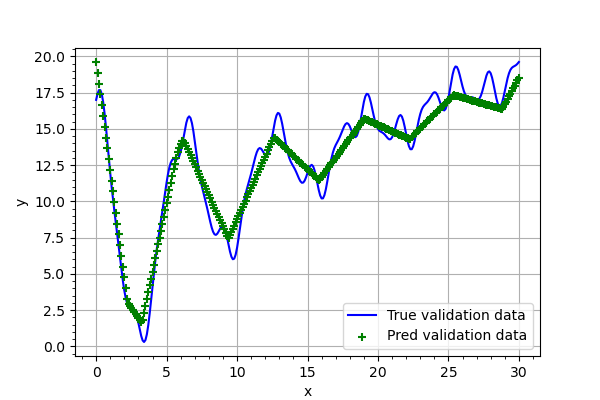

In [10]:
# Hyperparameters
learning_rate = 0.001 
num_epochs = 10
batch_size = 32
activation = nn.ReLU() 
criterion = nn.MSELoss()  

# Initialize model
neurons = 500
model = SingleLayerPerceptron(input_dim=1, hidden_dim=neurons, activation_func=activation, output_dim=1)
#neurons = [200,100]
#model = MLP_2layer(input_dim=1,output_dim=1,neurons=neurons, activation_func=activation)
optimizer = optim.AdamW(model.parameters(), lr=learning_rate)
if type(neurons) is list:
    nparams= calc_num_net_parameters(neurons.copy(), output_size=1)
else:
    nparams= calc_num_net_parameters(neurons, output_size=1)

# Training data params
training_samples=20000 
x_min, x_max=0,30

# Create and preprocess training data into 32 bit floats for PyTorch torch.Tensor objects
x_vals_train=sample_x_values(x_min, x_max, dx=0.00001, num_samples=training_samples).astype(np.float32)
y_vals_train = compute_y(x_vals_train).astype(np.float32)
x_vals_train_normalized, x_mean, x_std = normalize_data(x_vals_train)
y_vals_train_normalized, y_mean, y_std = normalize_data(y_vals_train)
X_train = torch.tensor(x_vals_train_normalized.reshape(len(x_vals_train),1), device='cpu')
y_train = torch.tensor(y_vals_train_normalized.reshape(len(y_vals_train),1), device='cpu')

# Create Validation data. In this simple case we are just sampling the true function, but realisitically it is taken from
# shuffled training data, i.e. for k-fold cross validation.
x_vals_valid=np.arange(x_min, x_max + 0.01, 0.1).astype(np.float32)
y_vals_valid = compute_y(x_vals_valid).astype(np.float32)
x_vals_valid_normalised = (x_vals_valid - x_mean) / x_std # DELIBERATELY Using normalisation from TRAINING data
y_vals_valid_normalised = (y_vals_valid - y_mean) / y_std # DELIBERATELY Using normalisation from TRAINING data
X_valid = torch.tensor(x_vals_valid_normalised.reshape(len(x_vals_valid),1), device='cpu')

# Format dataset using specialised PyTorch containers
# DataLoader re-shuffles the training data at each epoch.
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Training loop
train_losses = []
for epoch in range(num_epochs):
    total_loss = 0.0
    model.train() # Tell model we are in training mode, weights can be modified, later we switch to evaluation mode
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        batch_X, batch_y      = batch_X.float(), batch_y.float()
        outputs               = model(batch_X).squeeze()  # Ensure output shape matches target
        loss                  = criterion(outputs, batch_y.squeeze())  # Compute loss
        loss.backward()  # Apply backpropagation
        optimizer.step()  # Update weights
        total_loss += loss.item()
    train_loss = total_loss / len(train_loader)
    train_losses.append(train_loss)
    
    ############################# Task 1) Evaluate model using validation data ############################
    # Add relevant code here
    #print(f"Epoch [{epoch+1}/{num_epochs}], Training Loss: {train_loss:.5f}, Valid Loss: {valid_loss:.5f}")
    ###################################################################
    print(f"Epoch [{epoch+1}/{num_epochs}], Training Loss: {train_loss:.5f}")
print("\nTraining complete.")
plot_train_loss(train_losses, valid_loss=None, labels=["Epoch", "MSE Loss", "Training Loss"], figsize=(4,3))

############################# Task 2) Reloading best model before evaluation ######################
# Add relevant code here, but you will also need to add new stuff in other places
#model.load_state_dict(best_model_state)
###################################################################

model.eval() # Important to tell the model we're in evaluation model, ensures no weights are changed by accident
with torch.no_grad():
    valid_pred_normalized = np.squeeze(model(X_valid).detach().numpy())
y_vals_valid_predicted = (valid_pred_normalized * y_std) + y_mean # Unnormalise 
valid_loss = mean_squared_error(y_vals_valid_normalised, valid_pred_normalized)
print("Number of training samples:",training_samples)
print("For hyperparameters:")
print("Neurons:",neurons,"("+str(nparams)+" parameters)","\nNum Epochs:", num_epochs,
      "\nLearning Rate:",learning_rate,"\nBatch Size:",batch_size,"\nActivation:",activation)
print(f"Final epoch: [{epoch+1}/{num_epochs}], Training Loss: {train_loss:.5f}, Valid Loss: {valid_loss:.5f}")
print("Best Epoch and its train/valid loss??")

# interactive plot
%matplotlib ipympl 
doubleplot(x_vals_valid, y_vals_valid, x_vals_valid, y_vals_valid_predicted,
           labels=["x","y","True validation data","Pred validation data",""],figsize=(6,4))

# Appendix

## 1. Some example output
These are some results I got from running the 1-layer network and 2-layer network, ensuring they have a similar number of free parameters. As you can see, the 2-layer network had greater flexibility, managing to capture some of the turning points more smoothly, whereas the 1-layer model just stitches long linear lines together. 
<div style="display: flex; justify-content: space-between;">

  <div style="width: 48%;">
    <h3>1-layer Network</h3>
    <ul>
      <li><b>Training samples:</b> 20000</li>
      <li><b>Neurons:</b> 5000 (5001 parameters)</li>
      <li><b>Max epochs:</b> 200</li>
      <li><b>Learning Rate:</b> 0.001</li>
      <li><b>Batch Size:</b> 32</li>
      <li><b>Activation:</b> ReLU</li>
      <li><b>Best model from epoch:</b> 127</li>
      <li><b>Training Loss:</b> 0.022</li>
      <li><b>Validation Loss:</b> 0.015</li>
    </ul>
    <img src="SLP_run.png" alt="1-layer prediction plot" width="90%">
  </div>

  <div style="width: 48%; margin-left: 20px;">
    <h3>2-layer Network</h3>
    <ul>
      <li><b>Training samples:</b> 20000</li>
      <li><b>Neurons:</b> (100, 50) (5101 parameters)</li>
      <li><b>Max epochs:</b> 200</li>
      <li><b>Learning Rate:</b> 0.001</li>
      <li><b>Batch Size:</b> 32</li>
      <li><b>Activation:</b> ReLU</li>
      <li><b>Best model from epoch:</b> 200</li>
      <li><b>Training Loss:</b> 0.012</li>
      <li><b>Validation Loss:</b> 0.011</li>
    </ul>
    <img src="2layer_run.png" alt="2-layer prediction plot" width="90%">
  </div>

</div>



## 2. Package install requirements

Either add required packages to an existing environment or make a new one with the below commands. Note, if *conda install anaconda::XXXXX* doesn't work (stuck on solving, etc), first try *conda install XXXXX*, and then try *conda install conda-forge::XXXXX*.

> conda install anaconda::pip

> conda install anaconda::jupyter

> conda install anaconda::numpy

> conda install conda-forge::matplotlib

> conda install anaconda::ipywidgets

> conda install conda-forge::ipympl

> conda install anaconda::scipy

PyTorch should be downloaded from what their [website specifies](https://pytorch.org/get-started/locally/), go for the cpu version, not CUDA.

For a windows anaconda distribution you can do: 

> pip3 install torch torchvision torchaudio
